In [1]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import random as rd

In [2]:
df = pd.read_csv('CNMFE.csv').drop([0])

cols = [" C000"," C003"," C009"," C010"," C016"," C020"," C022"," C024"," C027"," C028"]

df_data = df[[" ",*cols]]
df_data = df_data.astype(float)
df_data.loc[6005:,' '] -= 216
df_data.loc[12010:,' '] -= 246
df_data.describe()

/usr/local/lib/python3.9/site-packages/IPython/core/interactiveshell.py:3146: DtypeWarning: Columns (0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106) have mixed types.Specify dtype option on import or set low_memory=False.
  has_raised = await self.run_ast_nodes(code_ast.body, cell_name,


,,C000,C003,C009,C010,C016,C020,C022,C024,C027,C028
count,18013.000000,18012.000000,18012.000000,18012.000000,18012.000000,18012.000000,18012.000000,18012.000000,18012.000000,18012.000000,18012.000000
mean,449.665617,3.301140,6.721746,4.999175,2.042033,1.396170,3.091872,18.115156,9.506635,1.778222,4.701605
std,259.476207,5.086396,11.537071,6.340346,4.281116,3.421575,4.733430,22.767987,15.496518,4.373218,6.106848
min,0.000000,-8.696693,-8.214556,-10.715180,-15.259280,-4.530520,-9.854396,-26.283170,-13.105420,-30.026660,-5.979754
25%,224.974383,1.223934,1.544614,2.144029,0.354185,-0.141441,1.043615,8.446815,2.971302,-0.074940,2.034833
50%,449.939922,2.067874,2.221971,3.199441,1.260994,0.605151,2.052317,14.857070,5.278449,1.610005,3.604242
75%,674.082500,3.211061,4.000513,4.804698,2.276168,1.523655,3.186519,20.742312,8.497508,3.249831,5.130542
max,899.056883,48.536620,69.560930,56.482110,40.426210,29.212760,36.164670,215.969100,127.377300,123.841400,69.429890


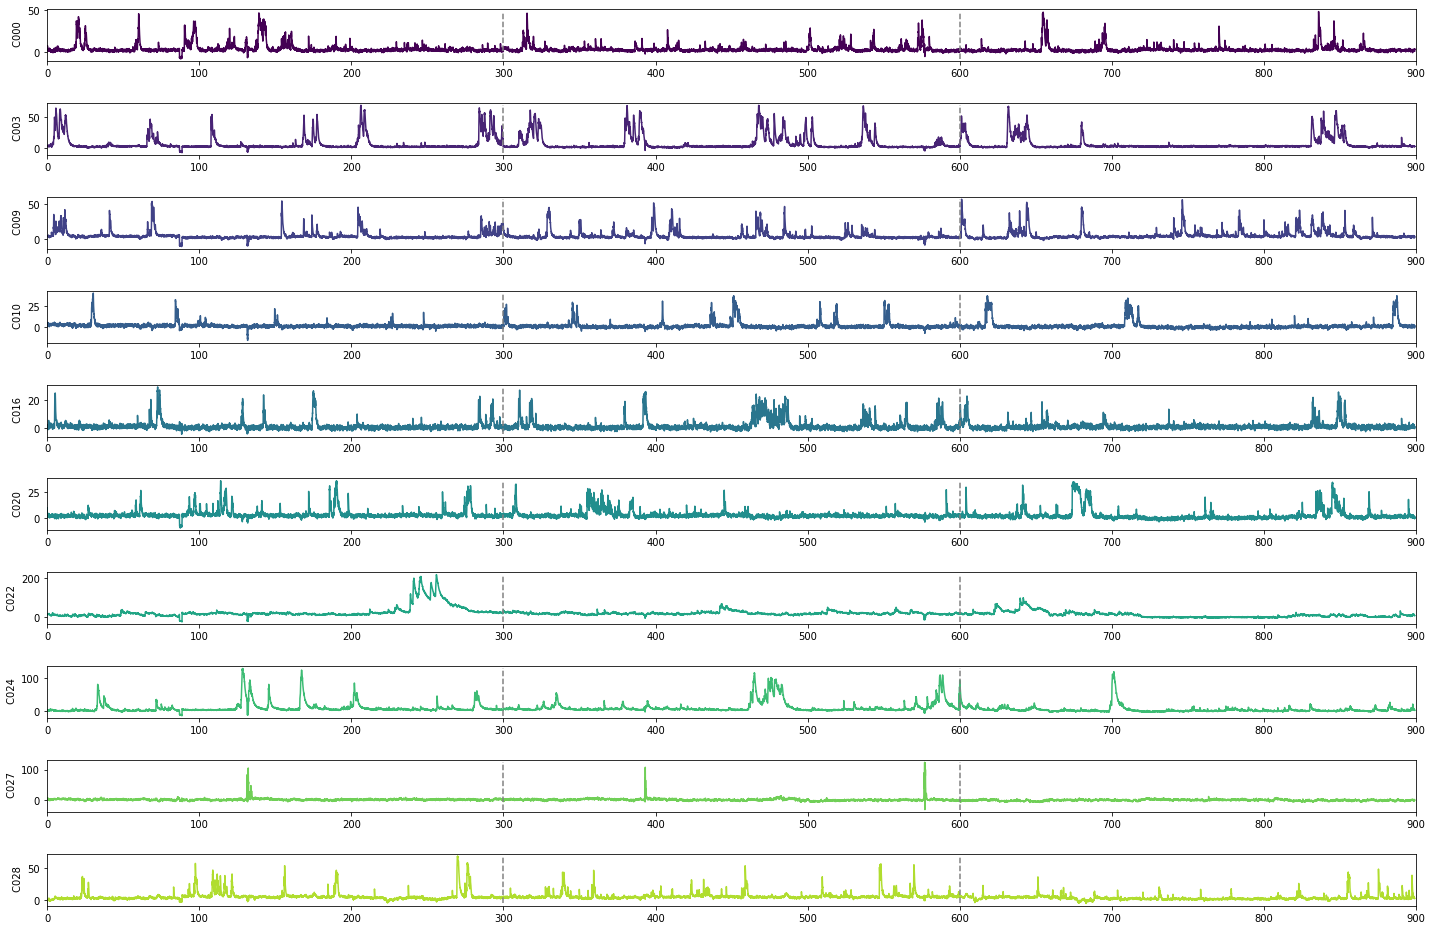

In [3]:
palette = sns.color_palette('viridis',as_cmap=True).colors

step = int(len(palette)/len(cols))

# UNCOMMENT THIS LINE TO MAKE ALL TRACES BLACK
# palette = ['#000' for i in range(len(palette))]

fig, ax = plt.subplots(len(cols), 1)
fig = plt.gcf()
fig.set_size_inches([20,len(cols)*1.322])

for i in range(len(cols)):
    sns.lineplot(data=df_data,x=" ",y=cols[i],ax=ax[i],color=palette[i*step])
    max_val = df_data[cols[i]].max()
    min_val = df_data[cols[i]].min()
    ax[i].plot([300,300],[min_val,max_val],linestyle='dashed',color='grey')
    ax[i].plot([600,600],[min_val,max_val],linestyle='dashed',color='grey')
    
    ax[i].set_xlim([0,900])
    
fig.tight_layout()
fig.savefig("CNMFE.jpg",dpi=500)

In [4]:
def get_rectangle(x,y,w,h,c):
    return mpatches.Rectangle((x,y),w,h, 
                        fill = True,
                        alpha=0.3,
                        color = c)

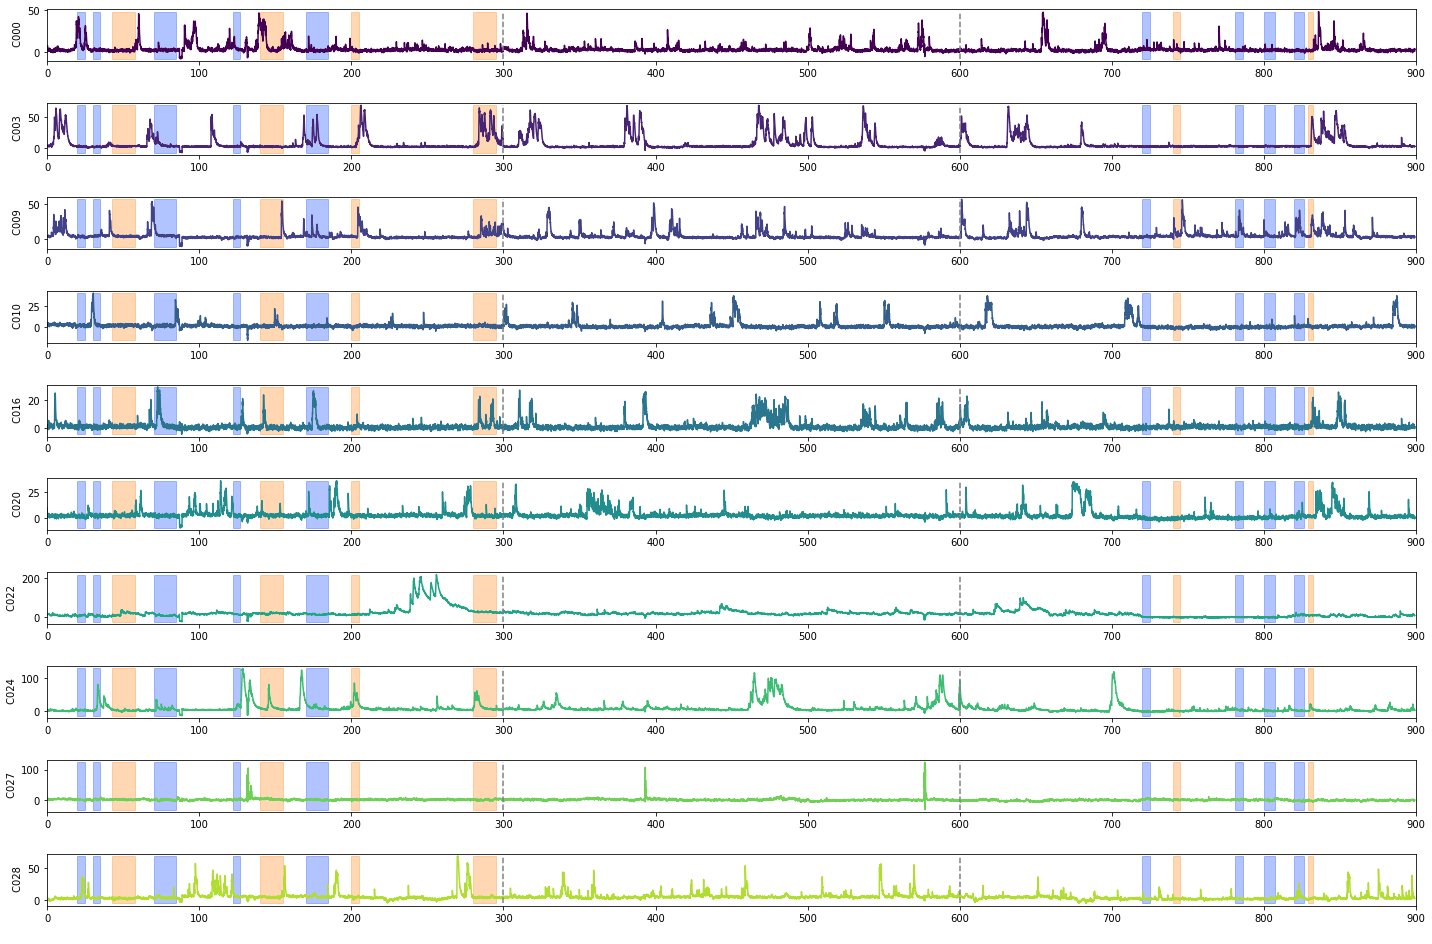

In [5]:
palette = sns.color_palette('viridis',as_cmap=True).colors

step = int(len(palette)/len(cols))

palette_r = sns.color_palette("bright")

# UNCOMMENT THIS LINE TO MAKE ALL TRACES BLACK
# palette = ['#000' for i in range(len(palette))]

fig, ax = plt.subplots(len(cols), 1)
fig = plt.gcf()
fig.set_size_inches([20,len(cols)*1.322])

data_x_locations = [[20,5],[30,5],[43,15],[70,15],[122,5],[140,15],[170,15],[200,5],[280,15],
                    [720,5],[740,5],[781,5],[800,7],[820,6],[829,3]]
colors = [0,0,1,0,0,1,0,1,1,0,1,0,0,0,1]

for i in range(len(cols)):
    
    max_val = df_data[cols[i]].max()
    min_val = df_data[cols[i]].min()
    
    for j,pair in enumerate(data_x_locations):
        ax[i].add_patch(get_rectangle(pair[0],min_val,pair[1],abs(min_val)+max_val,palette_r[colors[j]]))
    
    sns.lineplot(data=df_data,x=" ",y=cols[i],ax=ax[i],color=palette[i*step])
    ax[i].plot([300,300],[min_val,max_val],linestyle='dashed',color='grey')
    ax[i].plot([600,600],[min_val,max_val],linestyle='dashed',color='grey')
    
    ax[i].set_xlim([0,900])
    
fig.tight_layout()
fig.savefig("CNMFE_v2.jpg",dpi=500)